# Week 3 - Ames Housing: Cleaning and Outlier Detection

This notebook performs the Week 3 cleaning workflow using the supplied `AmesHousing_Uncleaned.csv`.

The supplied file contains **2,930 rows and 82 columns** and has **no exact duplicate rows**. Therefore, this notebook audits duplicates but does not remove any rows unless duplicates are actually found. Missing values are handled using the dataset-specific decisions below. Potential statistical outliers are flagged and inspected, not automatically deleted.

Run the cells from top to bottom. The cleaned CSV and quality reports are generated by the final export cells in this notebook.


## 1. Import the libraries and load the supplied raw CSV

Keep `AmesHousing_Uncleaned.csv` in the same folder as this notebook. The notebook reads that file directly so the cleaning process has a clear and reproducible input.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

input_file = "AmesHousing_Uncleaned.csv"

if not os.path.exists(input_file):
    raise FileNotFoundError(
        "Place AmesHousing_Uncleaned.csv in the same folder as this notebook."
    )

df_raw = pd.read_csv(input_file)
df = df_raw.copy()

print("Loaded:", input_file)
print("Initial shape:", df.shape)
print("Initial missing cells:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))

# This supplied source is expected to contain 2,930 rows and 82 columns.
# Stop if a different file was loaded by mistake.
assert df.shape == (2930, 82), (
    f"Unexpected dataset shape {df.shape}. Check that the correct raw CSV is being used."
)

# The supplied CSV has no exact duplicates. Keep this check in the notebook
# so any future duplicate rows are visible rather than silently ignored.
duplicate_count = int(df.duplicated().sum())
if duplicate_count > 0:
    print(f"Removing {duplicate_count} exact duplicate rows.")
    df = df.drop_duplicates().copy()
else:
    print("No exact duplicate rows found. No rows removed.")

print("Shape after duplicate check:", df.shape)


Loaded: AmesHousing_Uncleaned.csv
Initial shape: (2930, 82)
Initial missing cells: 15066
Exact duplicate rows: 0
No exact duplicate rows found. No rows removed.
Shape after duplicate check: (2930, 82)


## 2. First look at the dataset

Before changing anything, it is useful to see the first few rows, the column types, and the size of the dataset. This gives us a reference point for the cleaning work.

In [2]:
display(df.head())

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


Rows: 2930
Columns: 82
<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2930 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  Ho

## 3. Check for missing values

The first cleaning task is to find where values are missing. Looking at both the count and the percentage is more useful than looking at the count alone because the columns all have the same number of rows.

In [3]:
missing = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().sum() / len(df) * 100).round(2)
})

missing = missing[missing["Missing Values"] > 0].sort_values(
    "Missing Values", ascending=False
)

display(missing)

,Missing Values,Missing Percentage
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Garage Finish,159,5.43
Garage Cond,159,5.43
Garage Qual,159,5.43
Garage Type,157,5.36


## 4. Decide what the missing values mean

A missing value does not always mean that someone forgot to enter the data. In this dataset, several missing categorical values actually mean that the house does not have that feature. For example, a missing `Pool QC` means there is no pool, not that the pool quality was forgotten.

For those columns, replacing the missing value with `None` keeps that information instead of throwing it away.

For numerical columns, the strategy depends on the variable. For example, `Lot Frontage` can reasonably use its median because it is a continuous measurement and housing data can be skewed by unusually large properties.

In [4]:
# Missing categorical values that represent the absence of a feature
no_feature_cols = [
    "Alley", "Mas Vnr Type", "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure",
    "BsmtFin Type 1", "BsmtFin Type 2", "Fireplace Qu", "Garage Type",
    "Garage Finish", "Garage Qual", "Garage Cond", "Pool QC", "Fence",
    "Misc Feature"
]

for col in no_feature_cols:
    if col in df.columns:
        df[col] = df[col].fillna("None")

# Numerical measurements where a missing value means the feature is absent
zero_if_absent = [
    "Mas Vnr Area", "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF",
    "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath", "Garage Cars",
    "Garage Area"
]

for col in zero_if_absent:
    if col in df.columns:
        df[col] = df[col].fillna(0)

# Lot Frontage is a numerical measurement, so use the median.
if "Lot Frontage" in df.columns:
    df["Lot Frontage"] = df["Lot Frontage"].fillna(df["Lot Frontage"].median())

# If Garage Year is missing because there is no garage, use 0 as a clear marker.
if "Garage Yr Blt" in df.columns:
    df["Garage Yr Blt"] = df["Garage Yr Blt"].fillna(0)

print("Main missing-value replacements have been applied.")

Main missing-value replacements have been applied.


## 5. Check what is still missing

After the first cleaning pass, we check the dataset again. Any remaining missing values should be small enough to investigate rather than filling everything automatically.

In [5]:
remaining_missing = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().sum() / len(df) * 100).round(2)
})

remaining_missing = remaining_missing[
    remaining_missing["Missing Values"] > 0
].sort_values("Missing Values", ascending=False)

display(remaining_missing)

,Missing Values,Missing Percentage


If a few numerical values are still missing, using the median is a reasonable final step for this exploratory project. The median is less affected by extreme house prices and unusually large measurements than the mean.

In [6]:
# Median imputation for remaining numerical columns.
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

# Mode imputation for remaining categorical/text columns.
categorical_cols = df.select_dtypes(include=["object", "string"]).columns

for col in categorical_cols:
    if df[col].isna().any():
        mode = df[col].mode(dropna=True)
        if not mode.empty:
            df[col] = df[col].fillna(mode.iloc[0])

print("Remaining missing values:", int(df.isna().sum().sum()))


Remaining missing values: 0


## 6. Outlier detection with boxplots

The next step is to look for unusually high or low values. Boxplots are useful because they show the middle 50% of the data and make extreme observations easy to spot.

An outlier is not automatically a mistake. A large house or an expensive house can be a genuine observation, so these plots are mainly used to identify records that deserve a closer look.

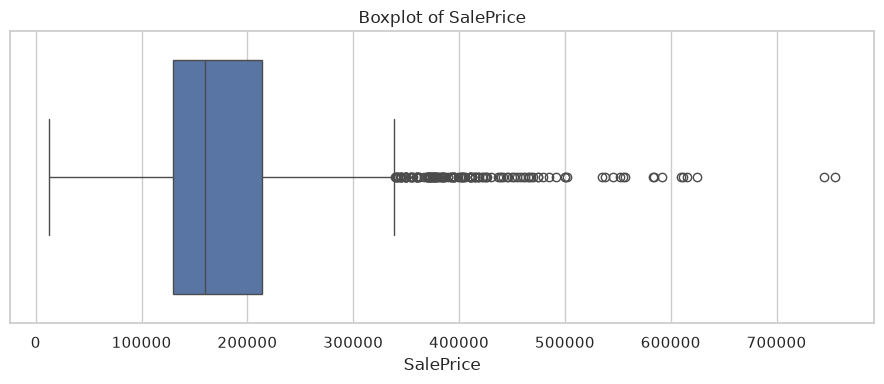

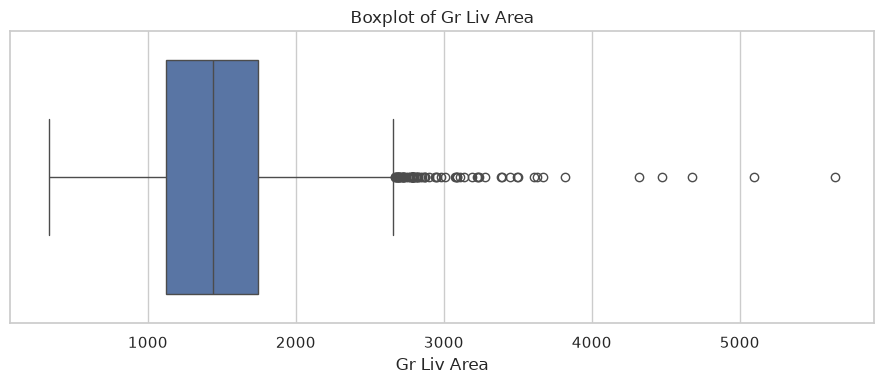

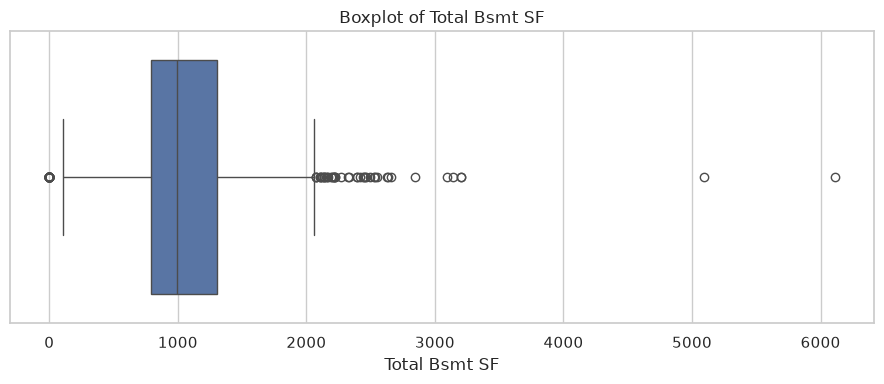

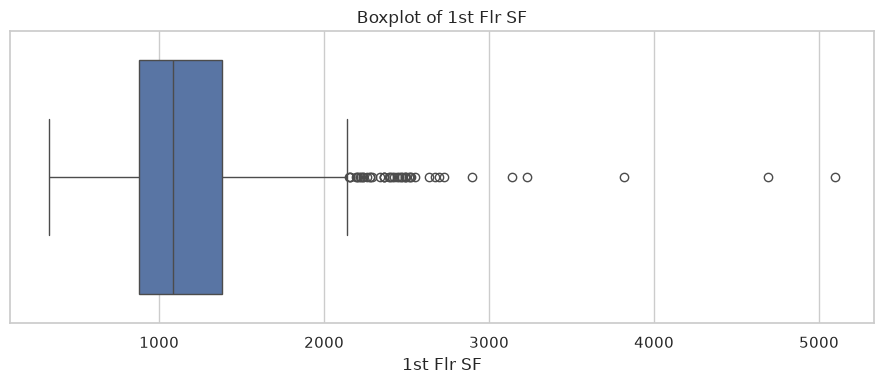

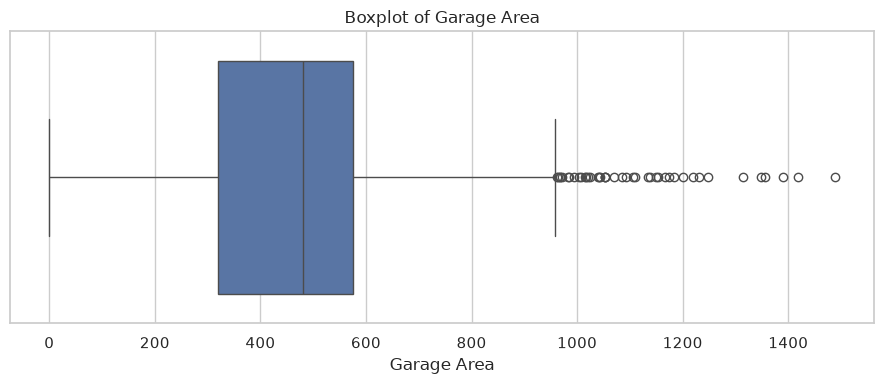

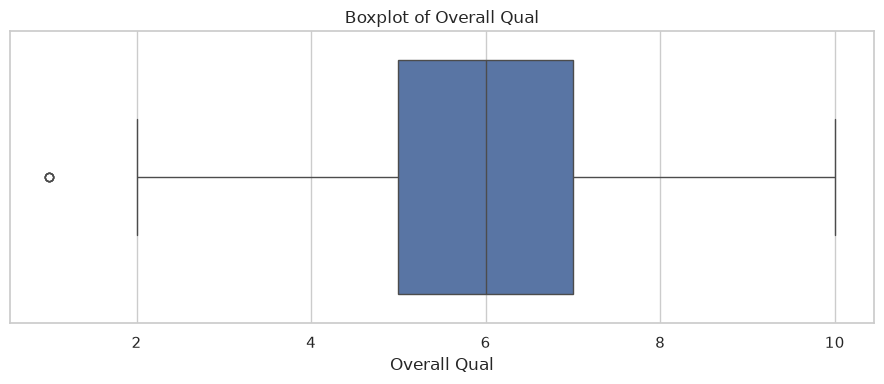

In [7]:
boxplot_cols = [
    "SalePrice", "Gr Liv Area", "Total Bsmt SF",
    "1st Flr SF", "Garage Area", "Overall Qual"
]

for col in boxplot_cols:
    if col in df.columns:
        plt.figure(figsize=(9, 4))
        sns.boxplot(x=df[col])
        plt.title(f"Boxplot of {col}")
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()

## 7. Z-score check

A Z-score tells us how far a value is from the average in terms of standard deviations. For this project, values with an absolute Z-score greater than 3 will be flagged as potential outliers.

This is only a screening method. We are not deleting every row that crosses the threshold.

In [8]:
zscore_cols = [
    "SalePrice", "Gr Liv Area", "Total Bsmt SF",
    "1st Flr SF", "Garage Area"
]

zscore_summary = []

for col in zscore_cols:
    if col in df.columns:
        values = df[col].astype(float)
        z = (values - values.mean()) / values.std(ddof=0)
        count = int((z.abs() > 3).sum())
        zscore_summary.append({
            "Column": col,
            "Potential Outliers (|Z| > 3)": count
        })

zscore_summary = pd.DataFrame(zscore_summary)
display(zscore_summary)

,Column,Potential Outliers (|Z| > 3)
0,SalePrice,45
1,Gr Liv Area,25
2,Total Bsmt SF,21
3,1st Flr SF,29
4,Garage Area,17


## 8. Inspect some potential outliers

Rather than removing the flagged rows immediately, we can inspect the most extreme observations. This helps separate unusual but believable houses from values that look like possible data-entry problems.

In [9]:
if "SalePrice" in df.columns and "Gr Liv Area" in df.columns:
    sale_z = (df["SalePrice"] - df["SalePrice"].mean()) / df["SalePrice"].std(ddof=0)
    area_z = (df["Gr Liv Area"] - df["Gr Liv Area"].mean()) / df["Gr Liv Area"].std(ddof=0)

    possible_outliers = df.loc[
        (sale_z.abs() > 3) | (area_z.abs() > 3),
        ["Order", "SalePrice", "Gr Liv Area", "Overall Qual", "Year Built"]
    ].copy()

    display(possible_outliers.sort_values("SalePrice", ascending=False).head(15))

,Order,SalePrice,Gr Liv Area,Overall Qual,Year Built
1767,1768,755000,4316,10,1994
1760,1761,745000,4476,10,1996
2445,2446,625000,3627,10,1995
1063,1064,615000,2470,10,2003
44,45,611657,2364,9,2009
432,433,610000,2674,10,2007
1637,1638,591587,2338,9,2006
2450,2451,584500,3500,9,1993
433,434,582933,2822,9,2008
2332,2333,556581,2868,9,2005


## 9. Cleaning decision

For this stage, the potential outliers are kept in the dataset unless there is clear evidence that a value is incorrect. The purpose of Week 3 is to identify and understand unusual observations, not to remove data just because it is extreme.

This also gives us a cleaner starting point for the Week 4 EDA, where the distributions and relationships between variables will be explored in more detail.

In [10]:
print("Final dataset shape:", df.shape)
print("Total remaining missing values:", int(df.isna().sum().sum()))
print("Remaining exact duplicate rows:", int(df.duplicated().sum()))

assert int(df.isna().sum().sum()) == 0, "Some missing values remain. Inspect the missing-value report."
assert int(df.duplicated().sum()) == 0, "Duplicate rows remain. Inspect before exporting."

display(df.head())


Final dataset shape: (2930, 82)
Total remaining missing values: 0
Remaining exact duplicate rows: 0


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,None,IR1,Lvl,...,0,None,None,None,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,None,Reg,Lvl,...,0,None,MnPrv,None,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,None,IR1,Lvl,...,0,None,None,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,None,Reg,Lvl,...,0,None,None,None,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,None,IR1,Lvl,...,0,None,MnPrv,None,0,3,2010,WD,Normal,189900


## 10. Save the cleaned dataset

This cell exports the cleaned dataset from the notebook. The original CSV remains unchanged. The output file is saved in the same folder and can be used by later project weeks.


In [11]:
output_file = "AmesHousing_Uncleaned_Cleaned.csv"
df.to_csv(output_file, index=False)

print(f"Saved cleaned dataset as: {output_file}")
print("Exported shape:", pd.read_csv(output_file).shape)


Saved cleaned dataset as: AmesHousing_Uncleaned_Cleaned.csv
Exported shape: (2930, 82)


## 11. Export data quality reports

These reports document the input and cleaned dataset. They are created when this notebook is run.

In [12]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Input rows", "Input columns", "Input missing cells",
        "Input exact duplicate rows", "Rows after duplicate check",
        "Final missing cells", "Final exact duplicate rows"
    ],
    "Value": [
        len(df_raw), df_raw.shape[1], int(df_raw.isna().sum().sum()),
        duplicate_count, len(df), int(df.isna().sum().sum()),
        int(df.duplicated().sum())
    ]
})

missingness_profile = pd.DataFrame({
    "Column": df_raw.columns,
    "Missing_Before": df_raw.isna().sum().values,
    "Missing_After": df.isna().sum().values,
    "Data_Type_After": df.dtypes.astype(str).values
})

quality_summary.to_csv("Week3_Data_Quality_Report.csv", index=False)
missingness_profile.to_csv("Week3_Missingness_Profile.csv", index=False)

display(quality_summary)
print("Saved Week3_Data_Quality_Report.csv")
print("Saved Week3_Missingness_Profile.csv")


,Metric,Value
0,Input rows,2930
1,Input columns,82
2,Input missing cells,15066
3,Input exact duplicate rows,0
4,Rows after duplicate check,2930
5,Final missing cells,0
6,Final exact duplicate rows,0


Saved Week3_Data_Quality_Report.csv
Saved Week3_Missingness_Profile.csv
